# Step 4 — Scores out of 100

**Paper:** Romera, Bergasa, Arroyo, *"Need Data for Driver Behaviour Analysis? Presenting the Public UAH-DriveSet"*, IEEE ITSC 2016.

### Where we are
Steps 2 and 3 gave us **7 risk numbers** per trip, like "6 hard brakes per 10 km" or "21% of the time
tailgating". Those are hard to compare: is 6 brakes worse than 21% tailgating?

The DriveSafe app solves this by giving every behaviour a **score out of 100** (100 = perfect,
0 = terrible), like a school report card, and the **overall score** is the average of the 7.
In this step we build the same report card from **our own** numbers.

| Score | Based on our risk number (from Step 2 / Step 3) |
|---|---|
| Accelerations | harsh accelerations per 10 km (with severity) |
| Brakings | harsh brakings per 10 km (with severity) |
| Turnings | sharp turns per 10 km (with severity) |
| Weaving | drift-and-correct per minute |
| Drifting | % of time more than 0.5 m off the lane centre |
| Overspeeding | % of time more than 10% over the speed limit |
| Car-following | % of time less than 0.5 s behind the car ahead |

All the code is in `scoring.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from uah_driveset import list_trips, load_summaries
import scoring as sc

plt.rcParams["figure.figsize"] = (12, 4)
COLORS = {"NORMAL": "tab:green", "AGGRESSIVE": "tab:red", "DROWSY": "tab:blue"}
ORDER = ["NORMAL", "DROWSY", "AGGRESSIVE"]

features = sc.add_weighted_events(pd.read_csv("../results/step3_trip_features.csv"))
app = load_summaries(list_trips()).set_index("trip_id").loc[features.trip_id].reset_index()
train = features.driver.isin(["D1", "D2", "D3"])
test = ~train
print(len(features), "trips:", train.sum(), "for fitting (D1-D3),", test.sum(), "for testing (D4-D6)")

40 trips: 21 for fitting (D1-D3), 19 for testing (D4-D6)


## 1. Counting harsh events with severity

A **medium or high** brake is more dangerous than a **low** one, so it should cost more points.
We use a simple rule: **a low event counts 1, a medium or high event counts 2**.

Example: a trip with 4 low brakes and 1 medium brake has 4×1 + 1×2 = **6 weighted brakes**.

In [2]:
features[["trip_id", "braking_per10km", "braking_high_med_per10km", "braking_weighted_per10km"]].head().round(2)

,trip_id,braking_per10km,braking_high_med_per10km,braking_weighted_per10km
0,20151110175712-16km-D1-NORMAL1-SECONDARY,0.00,0.00,0.00
1,20151110180824-16km-D1-NORMAL2-SECONDARY,2.50,0.00,2.50
2,20151111123124-25km-D1-NORMAL-MOTORWAY,1.20,0.00,1.20
3,20151111125233-24km-D1-AGGRESSIVE-MOTORWAY,2.92,1.25,4.17
4,20151111132348-25km-D1-DROWSY-MOTORWAY,2.80,1.60,4.40


## 2. The scoring formula

We use **one simple formula** for every behaviour, with two settings:

- **allowance**: a little risk is forgiven. Up to this amount, the score stays at **100**.
  (Even good drivers brake hard sometimes, and the sensors are not perfect.)
- **half_at**: every extra `half_at` units of risk above the allowance **halves** the score.

> **score = 100** if risk ≤ allowance
> **score = 100 × ½ ^ ((risk − allowance) ÷ half_at)** otherwise

### Example: braking (allowance = 2.5, half_at = 3.1)
| Weighted brakes per 10 km | Calculation | Score |
|---|---|---|
| 2 | below the allowance | **100** |
| 5.6 | 3.1 above the allowance → halved once | **50** |
| 8.7 | 6.2 above → halved twice | **25** |
| 11.8 | 9.3 above → halved three times | **12.5** |

Why this shape and not a straight line? With a straight line, a bad enough trip would go **below 0**.
With halving, the score drops quickly at first and then levels off near 0, and never goes negative.

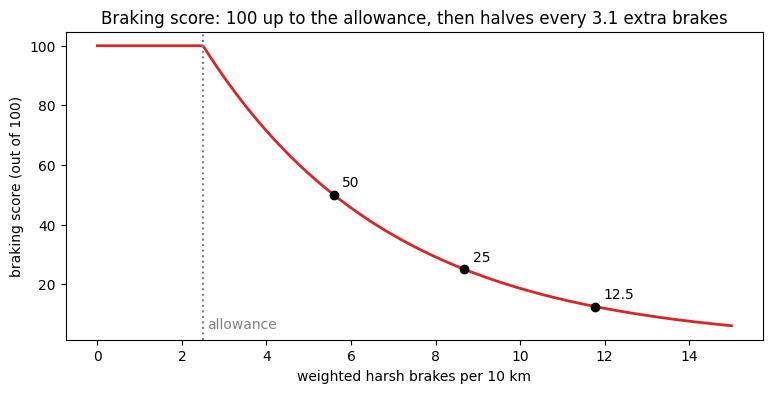

In [3]:
x = np.linspace(0, 15, 300)
p = sc.SCORE_PARAMS["brakings"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x, sc.behaviour_score(x, **p), color="tab:red", lw=2)
ax.axvline(p["allowance"], ls=":", color="grey")
ax.text(p["allowance"] + 0.1, 5, "allowance", color="grey")
for k in range(1, 4):
    xi = p["allowance"] + k * p["half_at"]
    ax.scatter([xi], [100 * 0.5 ** k], color="black", zorder=3)
    ax.annotate(f"{100 * 0.5 ** k:g}", (xi, 100 * 0.5 ** k), textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("weighted harsh brakes per 10 km")
ax.set_ylabel("braking score (out of 100)")
ax.set_title("Braking score: 100 up to the allowance, then halves every 3.1 extra brakes")
plt.show()

## 3. Choosing the allowance and half_at for each behaviour

Same idea as Steps 2 and 3: we **try many pairs** of (allowance, half_at), and keep the pair whose
scores are **closest to the app's own scores**. "Closest" = the smallest **average gap in points**
between our score and the app's score.

We fit on drivers **D1–D3 only** and keep **D4–D6 as the test**.

In [4]:
rows = []
for behaviour, column in sc.BEHAVIOURS.items():
    allowance, half_at, gap = sc.fit_curve(features.loc[train, column], app.loc[train, sc.APP_SCORES[behaviour]])
    rows.append({"behaviour": behaviour, "based on": column, "allowance": allowance, "half_at": half_at,
                 "avg gap on D1-D3 (points)": gap})
fitted = pd.DataFrame(rows).set_index("behaviour")
fitted

,based on,allowance,half_at,avg gap on D1-D3 (points)
behaviour,,,,
accelerations,acceleration_weighted_per10km,0.71,12.57,2.26
brakings,braking_weighted_per10km,2.50,3.09,9.14
turnings,turning_weighted_per10km,0.00,9.09,6.79
weaving,weaving_per_min,3.16,0.36,10.39
drifting,drifting_pct,0.00,21.54,8.02
overspeeding,speeding_pct,0.00,41.14,7.78
car_following,tailgating_pct,1.59,12.57,3.08


These are the values stored in `scoring.py` (`SCORE_PARAMS`). Some behaviours get an allowance
(braking, weaving, tailgating, a little for accelerations), others start losing points right away.

### How the fitted curves look
Each dot is one trip: its risk number (x) and **the app's** score (y). The line is **our** formula.
Hollow dots are the test drivers D4–D6.

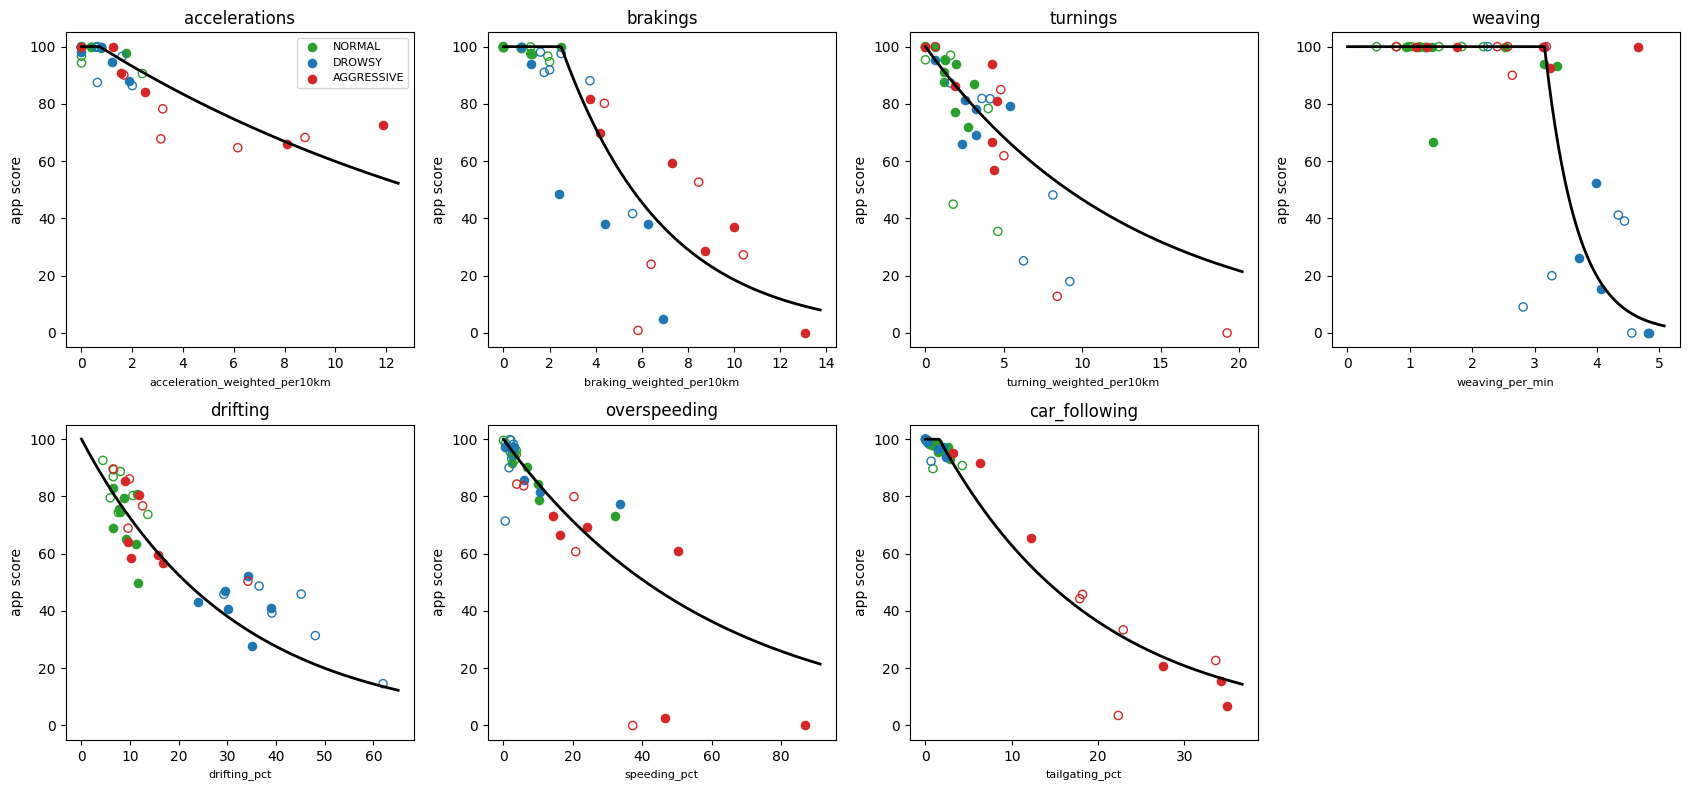

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, (behaviour, column) in zip(axes.flat, sc.BEHAVIOURS.items()):
    for b in ORDER:
        for subset, face in [(train, COLORS[b]), (test, "none")]:
            m = (features.behavior == b) & subset
            ax.scatter(features.loc[m, column], app.loc[m, sc.APP_SCORES[behaviour]],
                       facecolors=face, edgecolors=COLORS[b], s=35, label=b if face != "none" else None)
    x = np.linspace(0, features[column].max() * 1.05, 300)
    ax.plot(x, sc.behaviour_score(x, **sc.SCORE_PARAMS[behaviour]), color="black", lw=2)
    ax.set_title(behaviour)
    ax.set_xlabel(column, fontsize=8)
    ax.set_ylabel("app score")
    ax.set_ylim(-5, 105)
axes.flat[-1].axis("off")
axes.flat[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Our scores vs the app's scores (fair test on D4–D6)

In [6]:
ours = sc.score_trips(features)
rows = []
for behaviour in list(sc.BEHAVIOURS) + ["total"]:
    app_col = sc.APP_SCORES.get(behaviour, "score_total")
    gap = (ours[behaviour] - app[app_col]).abs()
    rows.append({"score": behaviour,
                 "avg gap D1-D3 (points)": round(gap[train].mean(), 1),
                 "avg gap D4-D6 (points)": round(gap[test].mean(), 1),
                 "correlation D4-D6": round(ours.loc[test, behaviour].corr(app.loc[test, app_col]), 2)})
pd.DataFrame(rows).set_index("score")

,avg gap D1-D3 (points),avg gap D4-D6 (points),correlation D4-D6
score,,,
accelerations,2.3,4.1,0.88
brakings,9.1,8.9,0.89
turnings,6.8,14.7,0.87
weaving,10.3,12.3,0.70
drifting,8.0,9.5,0.96
overspeeding,7.8,7.6,0.87
car_following,3.1,3.9,0.97
total,3.8,4.8,0.94


**How to read this:** for a new driver (D4–D6), our **overall score** is on average only about
**5 points** away from the app's (out of 100). Car-following and accelerations are within about 4 points.
Turning and weaving differ the most, as expected from Steps 2 and 3 (the app uses extra rules there).

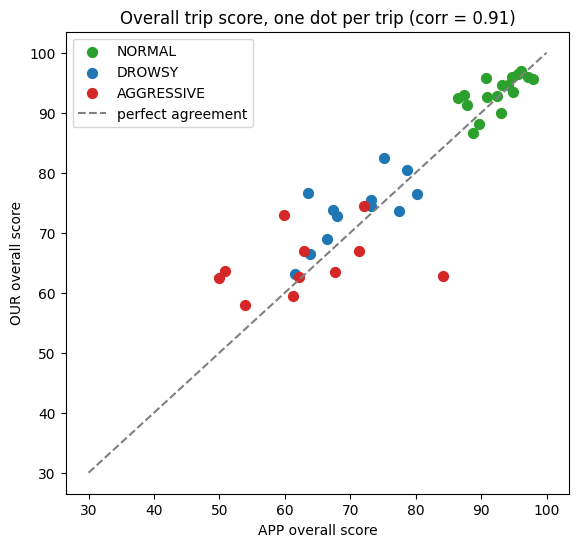

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for b in ORDER:
    m = features.behavior == b
    ax.scatter(app.loc[m, "score_total"], ours.loc[m, "total"], color=COLORS[b], label=b, s=50)
ax.plot([30, 100], [30, 100], ls="--", color="grey", label="perfect agreement")
ax.set_xlabel("APP overall score")
ax.set_ylabel("OUR overall score")
ax.set_title(f"Overall trip score, one dot per trip (corr = {ours.total.corr(app.score_total):.2f})")
ax.legend()
plt.show()

## 5. Scores by driving style

In [8]:
by_style = ours.assign(behavior=features.behavior).groupby("behavior").mean().reindex(ORDER).round(1)
by_style

,accelerations,brakings,turnings,weaving,drifting,overspeeding,car_following,total
behavior,,,,,,,,
NORMAL,99.1,100.0,89.0,98.1,76.4,92.2,98.3,93.3
DROWSY,98.2,80.9,74.0,40.4,31.1,92.0,99.4,73.7
AGGRESSIVE,82.9,39.0,71.1,89.5,66.8,64.7,40.1,64.9


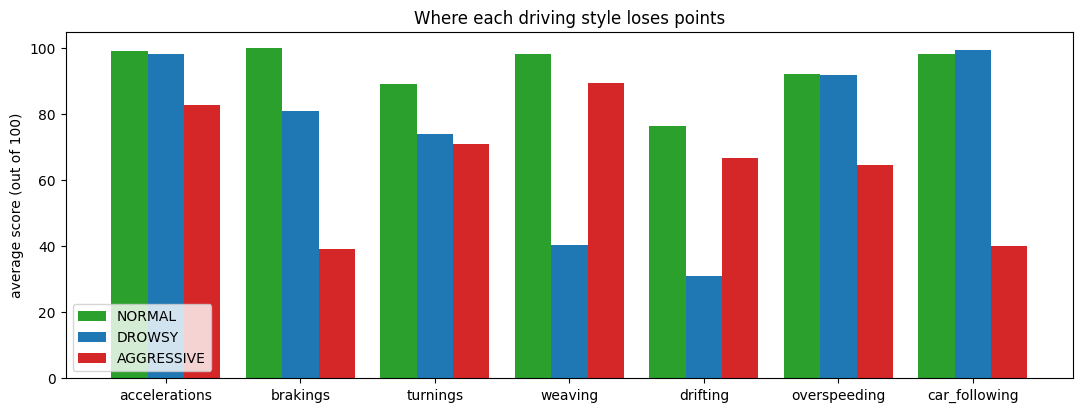

In [9]:
cols = list(sc.BEHAVIOURS)
fig, ax = plt.subplots(figsize=(13, 4.5))
w = 0.27
for i, b in enumerate(ORDER):
    ax.bar(np.arange(len(cols)) + (i - 1) * w, by_style.loc[b, cols], width=w, color=COLORS[b], label=b)
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols)
ax.set_ylabel("average score (out of 100)")
ax.set_ylim(0, 105)
ax.set_title("Where each driving style loses points")
ax.legend(loc="lower left")
plt.show()

**What the chart shows:**
- 🟢 **Normal** drivers score close to 100 on everything.
- 🔴 **Aggressive** drivers lose points on **brakings, turnings, overspeeding and car-following**.
- 🔵 **Drowsy** drivers lose points on **weaving and drifting**.

The **overall score** ranks them: Normal ≈ 93, Drowsy ≈ 74, Aggressive ≈ 65.

## 6. Example report cards

One trip of each style for driver D2 on the motorway, with the app's score next to ours.

In [10]:
def report_card(driver, behavior, road):
    i = features.index[(features.driver == driver) & (features.behavior == behavior) & (features.road == road)][0]
    rows = []
    for behaviour in list(sc.BEHAVIOURS) + ["total"]:
        app_col = sc.APP_SCORES.get(behaviour, "score_total")
        rows.append({"score": behaviour, "ours": ours.loc[i, behaviour], "app": app.loc[i, app_col]})
    return pd.DataFrame(rows).set_index("score")

cards = pd.concat({b: report_card("D2", b, "MOTORWAY") for b in ORDER}, axis=1)
cards

NORMAL        DROWSY       AGGRESSIVE      
                ours    app   ours   app       ours   app
score                                                    
accelerations   99.7   99.7   97.3  94.7       66.6  65.9
brakings       100.0   99.7  100.0  48.6       34.0  59.3
turnings        81.4   72.1   78.3  78.4       72.4  66.7
weaving        100.0  100.0   20.3  52.4       84.1  92.6
drifting        78.1   75.5   38.6  46.9       58.5  56.7
overspeeding    96.0   96.5   98.4  97.6       76.0  66.7
car_following   93.3   92.9   95.7  93.7       23.9  20.9
total           92.6   90.9   75.5  73.2       59.4  61.3


**Reading the report cards:** most scores are within a few points of the app's, and the overall
scores are very close (92.6 vs 90.9, 75.5 vs 73.2, 59.4 vs 61.3).

The biggest disagreement is **brakings on the drowsy trip** (ours 100, app 49). Our detector found
only a few brakes there, under the allowance, while the app gave the trip a low braking score.
The app probably also judges *how late* the driver braked, which a sleepy driver does, and that is
something the paper does not describe in detail.


## 7. Save the scores

In [11]:
out = features[["trip_id", "driver", "behavior", "road"]].join(ours)
out.to_csv("../results/step4_trip_scores.csv", index=False)
out.head()

,trip_id,driver,behavior,road,accelerations,brakings,turnings,weaving,drifting,overspeeding,car_following,total
0,20151110175712-16km-D1-NORMAL1-SECONDARY,D1,NORMAL,SECONDARY,100.0,100.0,78.8,100.0,69.8,58.1,100.0,86.7
1,20151110180824-16km-D1-NORMAL2-SECONDARY,D1,NORMAL,SECONDARY,100.0,100.0,86.7,100.0,69.0,89.1,94.4,91.3
2,20151111123124-25km-D1-NORMAL-MOTORWAY,D1,NORMAL,MOTORWAY,100.0,100.0,91.3,68.4,75.6,95.1,100.0,90.0
3,20151111125233-24km-D1-AGGRESSIVE-MOTORWAY,D1,AGGRESSIVE,MOTORWAY,100.0,68.8,70.5,5.6,74.8,42.8,77.3,62.8
4,20151111132348-25km-D1-DROWSY-MOTORWAY,D1,DROWSY,MOTORWAY,100.0,65.3,78.3,34.3,46.2,95.2,97.5,73.8


## Summary

| What | Result |
|---|---|
| Scoring formula | 100 up to an allowance, then the score **halves** every `half_at` units of extra risk |
| Settings | fitted per behaviour on D1–D3, to match the app's scores as closely as possible |
| Overall score on new drivers (D4–D6) | on average **≈ 5 points** from the app's |
| Agreement of overall score with the app | correlation ≈ **0.94** on D4–D6 (≈ 0.91 on all 40 trips) |
| Average overall score | Normal ≈ **93**, Drowsy ≈ **74**, Aggressive ≈ **65** |

**Next step (Step 5):** use these scores and risk numbers to **predict** whether each trip was
Normal, Drowsy or Aggressive, and see if we can beat the app's 90% accuracy from Step 1.